# TELECOM CUSTOMER CHURN PREDICTION - Version 2
### improving my v1 project with AutoML, a business threshold and SHAP

**Author:** Ragini Gupta
**Dataset:** ibm telco customer churn (kaggle)

## 1. Importing Libraries

In [1]:
import os 
import warnings
warnings.filterwarnings("ignore")
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split , cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score ,classification_report, ConfusionMatrixDisplay

from flaml import AutoML
import shap

## 2. Loading the Data

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")

print(f"{df.shape[0]:,} customers, {df.shape[1]} columns")
df.head()

7,043 customers, 21 columns


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 3. Cleaning the Data

In [3]:
# totalcharges is stored as text because of 11 blank rows
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# these 11 customers have tenure 0 (just joined, not billed yet) so total charges = 0
# in v1 i dropped them, now i keep them
df['TotalCharges'] = df['TotalCharges'].fillna(0)

# customerid is just an id, not useful
df = df.drop('customerID', axis=1)

# churn: yes = 1, no = 0
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

print("missing values left:", df.isnull().sum().sum())
print("churn rate:", round(df['Churn'].mean() * 100, 1), "%")


missing values left: 0
churn rate: 26.5 %


## 4. Creating New Features

In [19]:
addon_cols = ['OnlineSecurity', 'OnlineBackup', 'DeviceProtection',
              'TechSupport', 'StreamingTV', 'StreamingMovies']

def add_new_features(data):
    # how many extra services the customer has
    data['num_addons'] = (data[addon_cols] == 'Yes').sum(axis=1)
    # 1 if paying by automatic bank transfer / credit card
    data['auto_pay'] = data['PaymentMethod'].str.contains('automatic').astype(int)
    # 1 if fiber optic customer without tech support
    data['fiber_no_support'] = ((data['InternetService'] == 'Fiber optic') & (data['TechSupport'] != 'Yes')).astype(int)
    return data

df = add_new_features(df)
df[['num_addons', 'auto_pay', 'fiber_no_support']].head()

KeyError: "None of [Index(['OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',\n       'StreamingTV', 'StreamingMovies'],\n      dtype='str')] are in the [columns]"

## 5. Encoding and Train-Test Split

In [5]:
# text columns -> numbers
df = pd.get_dummies(df, dtype=int)

X = df.drop('Churn', axis=1)
y = df['Churn']

# stratify=y keeps the same churn % in train and test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("training customers:", X_train.shape[0])
print("testing customers :", X_test.shape[0])
print("train churn rate  :", round(y_train.mean() * 100, 1), "%")
print("test churn rate   :", round(y_test.mean() * 100, 1), "%")

training customers: 5634
testing customers : 1409
train churn rate  : 26.5 %
test churn rate   : 26.5 %


## 6. Scaling (only needed for logistic regression)

In [6]:
# scaler learns only from the training data (in v1 i scaled before splitting)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

## 7. Baseline Models (same as v1)

In [7]:
results = []   # stores the scores of every model

def check_model(name, pred, prob):
    acc = accuracy_score(y_test, pred)
    rec = recall_score(y_test, pred)
    pre = precision_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)
    print(name)
    print("accuracy  :", round(acc * 100, 2), "%")
    print("recall    :", round(rec * 100, 2), "%")
    print("precision :", round(pre * 100, 2), "%")
    print("roc auc   :", round(auc, 4))
    print()
    results.append([name, acc, rec, pre, auc])

# logistic regression
lr_model = LogisticRegression(max_iter=5000)
lr_model.fit(X_train_scaled, y_train)
check_model("Logistic Regression", lr_model.predict(X_test_scaled), lr_model.predict_proba(X_test_scaled)[:, 1])

# random forest
rf_model = RandomForestClassifier(n_estimators=210, max_depth=11, random_state=42)
rf_model.fit(X_train, y_train)
check_model("Random Forest", rf_model.predict(X_test), rf_model.predict_proba(X_test)[:, 1])

Logistic Regression
accuracy  : 80.41 %
recall    : 55.88 %
precision : 65.31 %
roc auc   : 0.8409

Random Forest
accuracy  : 79.99 %
recall    : 51.87 %
precision : 65.54 %
roc auc   : 0.837



## 8. AutoML with FLAML

In [8]:
# flaml tries different models and settings by itself and checks each one with 5-fold cross validation
automl = AutoML()
automl.fit(X_train, y_train,
           task="classification",
           metric="roc_auc",
           estimator_list=["lgbm", "xgboost", "rf", "extra_tree"],
           eval_method="cv",
           n_splits=5,
           time_budget=60,        # seconds
           seed=42,
           verbose=0)

best_model = automl.model.estimator

print("best model found:", automl.best_estimator)
print("cross validation roc auc:", round(1 - automl.best_loss, 4))

check_model("FLAML AutoML (" + automl.best_estimator + ")", best_model.predict(X_test), best_model.predict_proba(X_test)[:, 1])

best model found: lgbm
cross validation roc auc: 0.8507
FLAML AutoML (lgbm)
accuracy  : 79.99 %
recall    : 53.21 %
precision : 65.03 %
roc auc   : 0.8473



## 9. Comparing the Three Models

In [9]:
comparison = pd.DataFrame(results, columns=['model', 'accuracy', 'recall', 'precision', 'roc_auc'])
comparison = comparison.set_index('model').round(4)
comparison

,accuracy,recall,precision,roc_auc
model,,,,
Logistic Regression,0.8041,0.5588,0.6531,0.8409
Random Forest,0.7999,0.5187,0.6554,0.8370
FLAML AutoML (lgbm),0.7999,0.5321,0.6503,0.8473


## 10. Choosing the Threshold using Business Cost

offer cost: 50 | saved customer value: 777 | success rate: 0.3
best threshold: 0.2


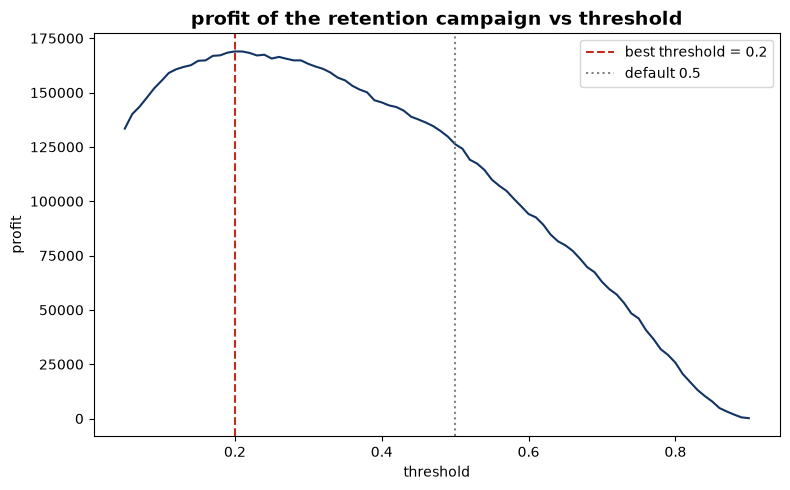

In [10]:
# assumptions (not real company data, can be changed according to your business)
offer_cost = 50                                      # cost of sending one retention offer
saved_value = round(df['MonthlyCharges'].mean() * 12)  # money kept if we save a customer (about 1 year)
success_rate = 0.30                                  # 30% of offers actually save the customer

print("offer cost:", offer_cost, "| saved customer value:", saved_value, "| success rate:", success_rate)

def campaign_profit(y_true, prob, threshold):
    contact = prob >= threshold                                   # customers who get the offer
    saved = y_true[contact].sum() * success_rate * saved_value    # money saved from real churners
    cost = contact.sum() * offer_cost                             # money spent on all offers
    return saved - cost

# probabilities for the training customers, each one predicted by a model that did not see it
train_prob = cross_val_predict(best_model, X_train, y_train, cv=5, method='predict_proba')[:, 1]

thresholds = np.arange(0.05, 0.91, 0.01)
profits = []
for t in thresholds:
    profits.append(campaign_profit(y_train, train_prob, t))

best_threshold = round(thresholds[np.argmax(profits)], 2)
print("best threshold:", best_threshold)

plt.figure(figsize=(8, 5))
plt.plot(thresholds, profits, color='#123463')
plt.axvline(best_threshold, color='#C42B1E', linestyle='--', label=f'best threshold = {best_threshold}')
plt.axvline(0.5, color='grey', linestyle=':', label='default 0.5')
plt.title('profit of the retention campaign vs threshold', fontsize=14, fontweight='bold')
plt.xlabel('threshold')
plt.ylabel('profit')
plt.legend()
plt.tight_layout()
plt.savefig("images/threshold_vs_profit.png", bbox_inches="tight")   # saves the chart for the README
plt.show()

## 11. Final Results on the Test Set

In [11]:
test_prob = best_model.predict_proba(X_test)[:, 1]

strategies = [["contact nobody", 1.01],
              ["contact everybody", 0.0],
              ["model with threshold 0.5", 0.5],
              [f"model with threshold {best_threshold}", best_threshold]]

for name, t in strategies:
    pred = (test_prob >= t).astype(int)
    recall = recall_score(y_test, pred) if pred.sum() > 0 else 0
    print(f"{name:28s} contacted: {pred.sum():5d}   recall: {recall:.2f}   profit: {campaign_profit(y_test, test_prob, t):,.0f}")

contact nobody               contacted:     0   recall: 0.00   profit: 0
contact everybody            contacted:  1409   recall: 1.00   profit: 16,729
model with threshold 0.5     contacted:   306   recall: 0.53   profit: 31,087
model with threshold 0.2     contacted:   654   recall: 0.84   profit: 40,260


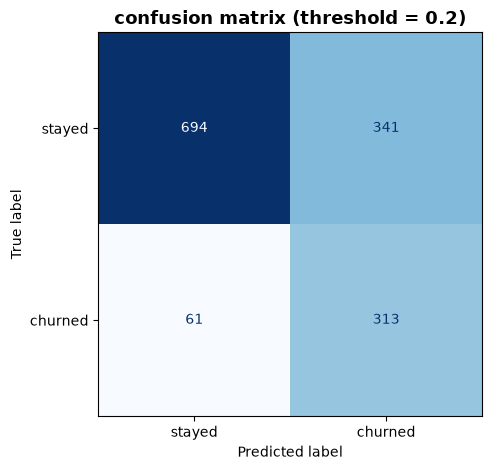

              precision    recall  f1-score   support

      stayed       0.92      0.67      0.78      1035
     churned       0.48      0.84      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.75      0.69      1409
weighted avg       0.80      0.71      0.73      1409



In [12]:
final_pred = (test_prob >= best_threshold).astype(int)

ConfusionMatrixDisplay.from_predictions(y_test, final_pred, display_labels=['stayed', 'churned'], cmap='Blues', colorbar=False)
plt.title(f'confusion matrix (threshold = {best_threshold})', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", bbox_inches="tight")
plt.show()

print(classification_report(y_test, final_pred, target_names=['stayed', 'churned']))

## 12. SHAP - why does the model predict churn?

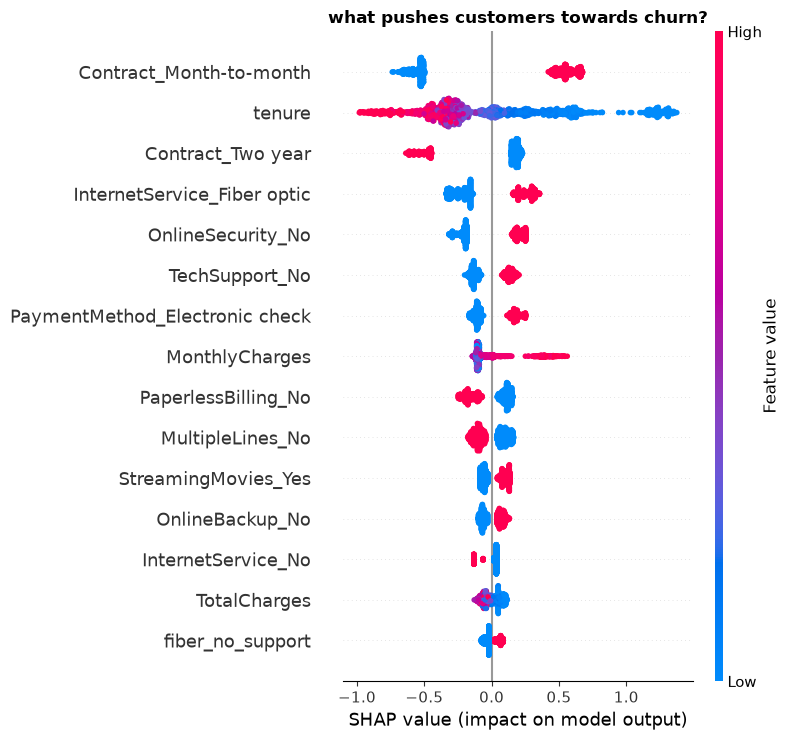

In [13]:
explainer = shap.TreeExplainer(best_model)
shap_values = explainer.shap_values(X_test)

# some models give shap values for both classes, we only need the churn class
if isinstance(shap_values, list):
    shap_values = shap_values[1]
if len(shap_values.shape) == 3:
    shap_values = shap_values[:, :, 1]

shap.summary_plot(shap_values, X_test, max_display=15, show=False)
plt.title('what pushes customers towards churn?', fontweight='bold')
plt.tight_layout()
plt.savefig("images/shap_summary.png", bbox_inches="tight")
plt.show()

churn probability: 90.6 %


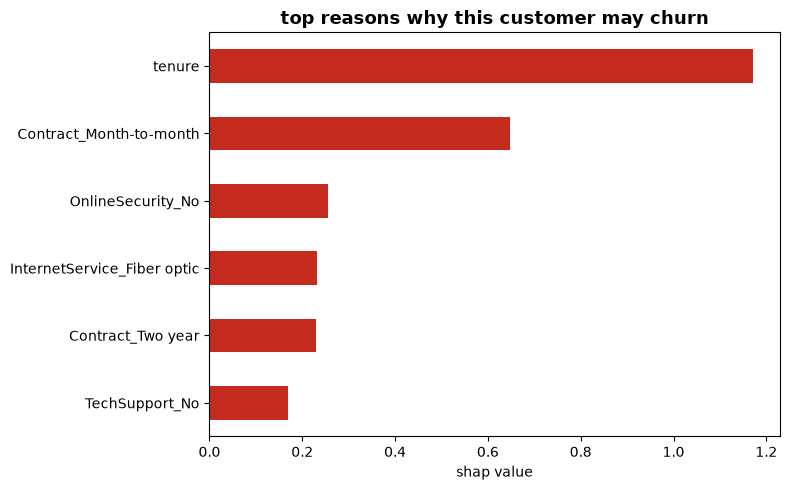

In [17]:
# explaining one customer - the one with the highest churn probability
i = test_prob.argmax()
print("churn probability:", round(test_prob[i] * 100, 1), "%")

contrib = pd.Series(shap_values[i], index=X_test.columns)
top = contrib.sort_values().tail(6)     # the 6 biggest reasons for churn

plt.figure(figsize=(8, 5))
top.plot(kind='barh', color='#C42B1E')
plt.title('top reasons why this customer may churn', fontsize=13, fontweight='bold')
plt.xlabel('shap value')
plt.tight_layout()
plt.savefig("images/one_customer_reasons.png", bbox_inches="tight")
plt.show()

## 13. Saving the Model

In [18]:
os.makedirs("models", exist_ok=True)

joblib.dump(best_model, "models/churn_model.pkl")
joblib.dump(list(X.columns), "models/model_columns.pkl")
joblib.dump(best_threshold, "models/threshold.pkl")

print("model, column names and threshold saved in the models folder")

model, column names and threshold saved in the models folder


## 14. Testing the Saved Model on a New Customer

In [20]:
model = joblib.load("models/churn_model.pkl")
model_columns = joblib.load("models/model_columns.pkl")
threshold = joblib.load("models/threshold.pkl")

# a new customer (values are made up)
new_customer = pd.DataFrame([{
    'gender': 'Female', 'SeniorCitizen': 0, 'Partner': 'No', 'Dependents': 'No', 'tenure': 2,
    'PhoneService': 'Yes', 'MultipleLines': 'No', 'InternetService': 'Fiber optic',
    'OnlineSecurity': 'No', 'OnlineBackup': 'No', 'DeviceProtection': 'No', 'TechSupport': 'No',
    'StreamingTV': 'No', 'StreamingMovies': 'No', 'Contract': 'Month-to-month',
    'PaperlessBilling': 'Yes', 'PaymentMethod': 'Electronic check',
    'MonthlyCharges': 80.0, 'TotalCharges': 160.0}])

# same steps as training
new_customer = add_new_features(new_customer)
new_customer = pd.get_dummies(new_customer, dtype=int)
new_customer = new_customer.reindex(columns=model_columns, fill_value=0)   # same columns as training

prob = model.predict_proba(new_customer)[0, 1]
print("churn probability:", round(prob * 100, 1), "%")
print("will we send a retention offer?", "YES" if prob >= threshold else "NO")

churn probability: 70.6 %
will we send a retention offer? YES


## Conclusion

- the three models give almost the same accuracy (about 80%), the difference is mainly in recall
- choosing the threshold using business cost matters more than the model itself
- full explanation, results and limitations are in the README